In [1]:
import qiskit
print(qiskit.__version__)

2.5.2


In [2]:
import numpy as np
from math import gcd, pi
from fractions import Fraction
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector


In [3]:
N, a = 15, 7 # N = number to factor, a = co-prime integer with N
n, m = 4, 8 # n = number of work qubits, m = number of counting qubits

def M_gate(b, N, n):
    dim = 2**n  #2^n (qubit space)
    M = np.zeros((dim, dim)) # start with an all-zero dim x dim matrix, fill in the 1s 
    for x in range(dim): # x = input basis state |x>
        if x < N:
            y = (b * x) % N # |x> -> |b*x mod N>
        else:
            y = x #x >= N: leave unchanged so M stays unitary
        M[y, x] = 1 # when input is x output y
    return UnitaryGate(M, label=f"M_{b}")  # wrap matrix M as a Qiskit gate (checks unitarity), named M_b in drawings

def my_qft(m):
    qc = QuantumCircuit(m, name="QFT") # empty m-qubit circuit, shown as "QFT" when boxed
    for t in range(m - 1, -1, -1): # loop from m-1 to 0
        qc.h(t) # H on qubit t: writes first digit 0.x_t into its phase
        for c in range(t - 1, -1, -1): # every lower qubit c = t-1, ..., 0 acts as control
            qc.cp(pi / 2**(t - c), c, t) # controlled phase: adds next binary digit x_c / 2^(t-c+1)
    for t in range(m // 2): # swap pairs (0, m-1), (1, m-2), ...
        qc.swap(t, m - 1 - t)# reverse qubit order to match the QFT definition
    return qc


In [4]:
count = QuantumRegister(m, "count") # m counting qubits: estimate the phase s/r (read out after iQFT)
work  = QuantumRegister(n, "work") # n work qubits: hold x (mod N), acted on by controlled-M_b
c     = ClassicalRegister(m, "c") # m classical bits: store the measurement result of count
shor_qc = QuantumCircuit(count, work, c) # full circuit: count = q0..q(m-1), work = q(m)..q(m+n-1)

shor_qc.x(work[0]) # work = |1> starting value
shor_qc.h(count) # H on all counting qubits: equal superposition of |0>..|2^m - 1>
for j in range(m): # one controlled gate per counting qubit j = 0..m-1
    b = pow(a, 2**j, N) # b = a^(2^j) mod N   -> compute the top exponent 2^j first: a^(2^j) != (a^2)^j
#   j = 0: 2^0 = 1 -> 7^1 = 7                     -> b = 7
#   j = 1: 2^1 = 2 -> 7^2 = 49   ≡ 4 (mod 15)     -> b = 4
#   j = 2: 2^2 = 4 -> 7^4 = 2401 ≡ 1 (mod 15)     -> b = 1

    cMb = M_gate(b, N, n).control(1) # C-M_b = I ⊗ |0><0| + M_b ⊗ |1><1|  (apply M_b only if control = 1)
    shor_qc.append(cMb, [count[j]] + list(work)) # control = count[j], targets = all work qubits
                                                    # -> overall: |k>|1>  ->  |k>|a^k mod N>
iqft = my_qft(m).inverse()
iqft.name = "QFT†"
shor_qc.compose(iqft, qubits=count, inplace=True) # apply QFT† to counting qubits
shor_qc.measure(count, c)

In [ ]:
sim = AerSimulator()
counts = sim.run(transpile(shor_qc, sim), shots=2048).result().get_counts()
print(counts)

for bits in counts:
    y = int(bits, 2) # binary string -> integer y
    phase = y / 2**m # estimated phase y/2^m ≈ s/r
    f1 = Fraction(phase) #from decimal to fraction
    f2 = f1.limit_denominator(N)  # find the closest value with denominator <= N. continued fraction expansion
    r  = f2.denominator #extract denominator
    ok = r % 2 == 0 and pow(a, r, N) == 1 # valid only if r is even AND a^r ≡ 1 (mod N)
    msg = f"factors {gcd(pow(a, r//2) - 1, N)}, {gcd(pow(a, r//2) + 1, N)}" if ok else "fail"
    # a^r - 1 = (a^(r/2) - 1)(a^(r/2) + 1) ≡ 0 mod N -> gcd gives factors
    print(f"y={y:3d}  phase={phase:.3f}  r={r}  {msg}") # y, phase, r candidate, result

{'10000000': 497, '01000000': 507, '11000000': 524, '00000000': 520}
y=128  phase=16.000  r=1  fail
y= 64  phase=8.000  r=1  fail
y=192  phase=24.000  r=1  fail
y=  0  phase=0.000  r=1  fail


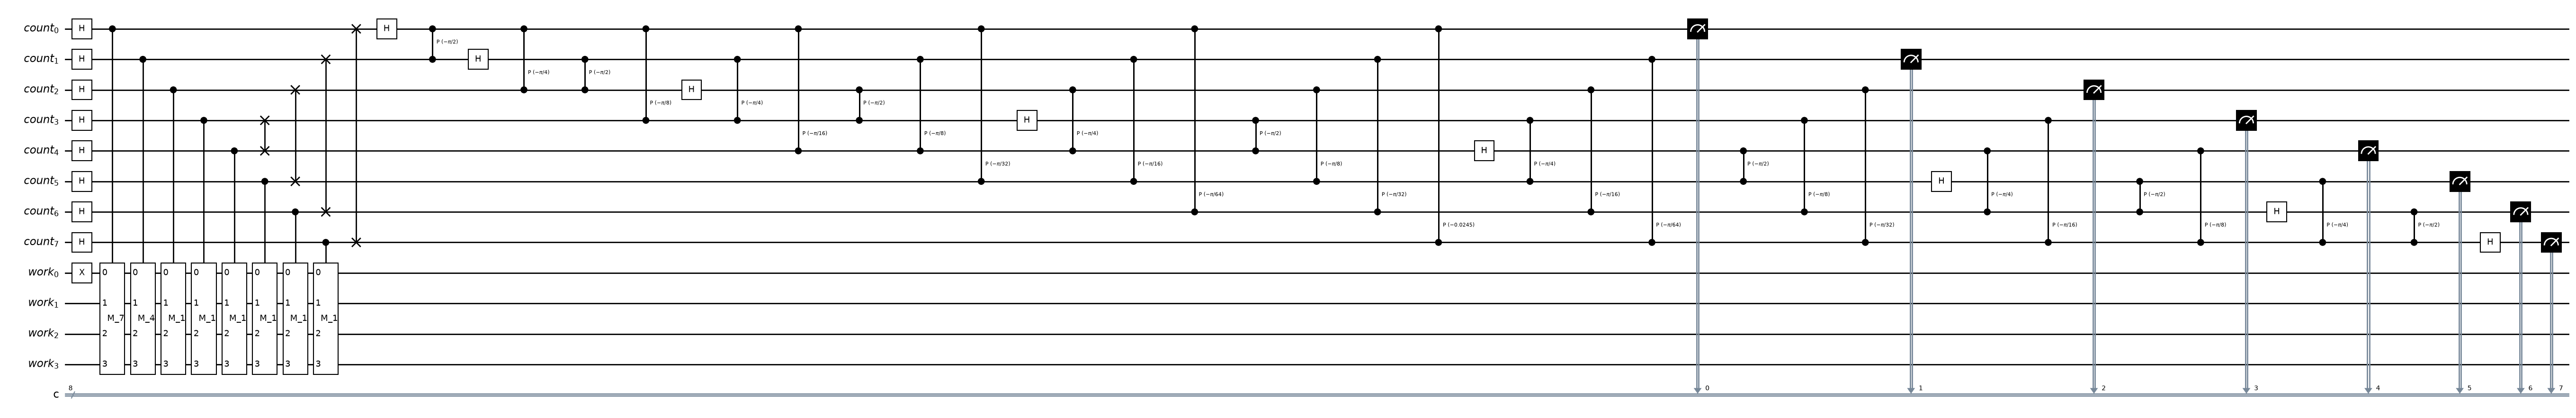

In [14]:
shor_qc.draw("mpl", style="bw", fold=-1)

In [5]:
N, a = 15, 7
n, m = 4, 3          # only 3 counting qubits (8 states) so the output stays short

# M_gate and my_qft: use your existing functions

def show(qc, title):
    sv = Statevector(qc)                 # current state vector, no measurement
    print(f"\n=== {title} ===")
    for idx, amp in enumerate(sv.data):
        if abs(amp) > 1e-6:              # print non-zero terms only
            k = idx % 2**m               # lower m bits = count register value
            w = idx >> m                 # upper n bits = work register value
            print(f"  |count={k}>|work={w:2d}>  amp={amp.real:+.3f}{amp.imag:+.3f}j  prob={abs(amp)**2:.3f}")

count = QuantumRegister(m, "count")
work  = QuantumRegister(n, "work")
qc = QuantumCircuit(count, work)

show(qc, "0) initial state")
qc.x(work[0]);  show(qc, "1) work = |1>")
qc.h(count);    show(qc, "2) H on count register")
for j in range(m):
    b = pow(a, 2**j, N)
    qc.append(M_gate(b, N, n).control(1), [count[j]] + list(work))
    show(qc, f"3.{j}) controlled-M_{b} (control = count[{j}])")
qc.compose(my_qft(m).inverse(), qubits=count, inplace=True)
show(qc, "4) after inverse QFT")
print("\ncount probabilities:", Statevector(qc).probabilities_dict(qargs=list(range(m)), decimals=3))


=== 0) initial state ===
  |count=0>|work= 0>  amp=+1.000+0.000j  prob=1.000

=== 1) work = |1> ===
  |count=0>|work= 1>  amp=+1.000+0.000j  prob=1.000

=== 2) H on count register ===
  |count=0>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=1>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=2>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=3>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=4>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=5>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=6>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=7>|work= 1>  amp=+0.354+0.000j  prob=0.125

=== 3.0) controlled-M_7 (control = count[0]) ===
  |count=0>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=2>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=4>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=6>|work= 1>  amp=+0.354+0.000j  prob=0.125
  |count=1>|work= 7>  amp=+0.354+0.000j  prob=0.125
  |count=3>|work= 7>  amp=+0.354+0.000j  prob=0.125
  |count=5>|work= 7>  amp=+0.354+0.00